In [2]:
import pandas as pd 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix,roc_auc_score
from xgboost import XGBClassifier
import joblib
import os

In [3]:
df = pd.read_csv("credigo_credit_default_dataset.csv")


In [4]:
df.head(5)

,customer_age,marital_status,education,employment_type,monthly_income,employment_tenure_months,total_account_balance,total_debt,credit_score,credit_utilization,loan_amount,loan_term_months,previous_loan_count,late_payment_count,default_flag
0,55,Single,Diploma,Part-time,20200.0,159,21200.0,154000.0,445,88.9,363000.0,36,5,7,1
1,53,Married,Bachelor,Full-time,52200.0,305,127000.0,378000.0,543,49.9,277000.0,48,6,1,0
2,30,Single,Bachelor,Self-employed,46800.0,25,41500.0,108000.0,681,44.1,518000.0,6,2,1,0
3,54,Divorced,Bachelor,Freelance,17700.0,28,21900.0,28000.0,599,50.6,99000.0,36,4,2,0
4,37,Single,High School,Full-time,18600.0,22,26600.0,145000.0,500,81.9,146000.0,24,0,0,0


In [5]:
x = df.drop(columns=["default_flag"])
y = df["default_flag"]

In [7]:
categorical_feature = ["marital_status","education","employment_type"] #ใช้ Onehotcoder แปลง
numerical_feature = [] # ใช้ StandardScaler() หน้าที่ของมันคือปรับ Scale ของตัวเลขให้มีค่าเฉลี่ยใกล้ 0 และส่วนเบี่ยงเบนมาตรฐานใกล้ 1
for col in x.columns :  
    if col not in categorical_feature : 
        numerical_feature.append(col)

In [8]:
preprocess = ColumnTransformer(transformers=[("num",StandardScaler(),numerical_feature),("cat",OneHotEncoder(),categorical_feature)])

# Pipeline 
model_lgs = Pipeline(steps=[("preprocess", preprocess),("classifier", LogisticRegression(max_iter=1000))])
model_rf = Pipeline(steps=[("preprocess", preprocess),("classifier", RandomForestClassifier( n_estimators=500,max_depth=5,min_samples_split=5,min_samples_leaf=1,max_features="sqrt",random_state=42,class_weight="balanced_subsample",n_jobs=-1,oob_score=True))])
model_xg = Pipeline(steps=[("preprocess",preprocess),("classifier",XGBClassifier(n_estimators=500,max_depth=2,learning_rate=0.01,subsample=1.0,colsample_bytree=0.8,min_child_weight=5,objective="binary:logistic",eval_metric="logloss",random_state=42,n_jobs=-1,reg_lambda=10))])
# Spilt 

x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=0)

In [13]:
# Logistic Regression
model_lgs.fit(x_train,y_train)
y_pred_lgs = model_lgs.predict(x_test)
y_prob_lgs = model_lgs.predict(x_test)

# Randomforest
model_rf.fit(x_train,y_train)
y_pred_rf = model_rf.predict(x_test)
y_prob_rf = model_rf.predict(x_test)

# XGBOOST 
model_xg.fit(x_train,y_train)
y_pred_xg = model_xg.predict(x_test)
y_prob_xg =model_xg.predict(x_test)

In [15]:
preprocessor = model_rf.named_steps["preprocess"]

encoder = (
    preprocessor
    .named_transformers_["cat"]
)

for feature, categories in zip(
    ["marital_status", "education", "employment_type"],
    encoder.categories_
):
    print(f"{feature}: {categories}")

marital_status: ['Divorced' 'Married' 'Single' 'Widowed']
education: ['Bachelor' 'Diploma' 'Doctorate' 'High School' 'Master']
employment_type: ['Freelance' 'Full-time' 'Part-time' 'Self-employed' 'Unemployed']


In [122]:
# Evaluate Model Logistic 
print("Classification  Logistic Report:")
print(classification_report(y_test, y_pred_lgs))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lgs))

print("ROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_lgs))

Classification  Logistic Report:
              precision    recall  f1-score   support

           0       0.83      0.99      0.90      1643
           1       0.51      0.06      0.11       357

    accuracy                           0.82      2000
   macro avg       0.67      0.52      0.51      2000
weighted avg       0.77      0.82      0.76      2000

Confusion Matrix:
[[1622   21]
 [ 335   22]]
ROC-AUC Score:
0.5244215762994181


In [123]:
# Evaluate Model Randomforest
print("Classification Randomforest Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("ROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_rf))

Classification Randomforest Report:
              precision    recall  f1-score   support

           0       0.89      0.74      0.81      1643
           1       0.32      0.56      0.41       357

    accuracy                           0.71      2000
   macro avg       0.60      0.65      0.61      2000
weighted avg       0.78      0.71      0.74      2000

Confusion Matrix:
[[1222  421]
 [ 158  199]]
ROC-AUC Score:
0.6505921906194005


In [124]:
# Evaluate Model XGBOOST
print("Classification XG BOOST Report:")
print(classification_report(y_test, y_pred_xg))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xg))

print("ROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_xg))

Classification XG BOOST Report:
              precision    recall  f1-score   support

           0       0.83      0.99      0.90      1643
           1       0.61      0.04      0.07       357

    accuracy                           0.82      2000
   macro avg       0.72      0.52      0.49      2000
weighted avg       0.79      0.82      0.75      2000

Confusion Matrix:
[[1634    9]
 [ 343   14]]
ROC-AUC Score:
0.5168689508670176


In [125]:
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

# ---------- 1. ทำนาย probability ----------
y_prob_rf = model_rf.predict_proba(x_test)[:, 1]

# ---------- 2. วัด AUC ใหม่ ----------
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_prob_rf):.4f}")

# ---------- 3. ฟังก์ชัน Expected Profit ----------
def expected_profit(y_true, y_prob, t, profit_good=1.0, loss_bad=5.0):
    y_true = np.asarray(y_true).astype(int)
    y_pred = (y_prob >= t).astype(int)
    tp = ((y_true == 1) & (y_pred == 1)).sum()   # อนุมัติหนี้เสีย
    tn = ((y_true == 0) & (y_pred == 0)).sum()   # อนุมัติลูกค้าดี
    fn = ((y_true == 1) & (y_pred == 0)).sum()   # ปฏิเสธหนี้เสีย
    fp = ((y_true == 0) & (y_pred == 1)).sum()   # ปฏิเสธลูกค้าดี
    return tn * profit_good - tp * loss_bad, (tp, tn, fn, fp)

# ---------- 4. วน threshold ----------
print(f"\n{'t':>6} | {'TP':>4} {'TN':>5} {'FN':>4} {'FP':>4} | {'Profit':>8}")
print("-" * 50)
for t in [0.15, 0.20, 0.25, 0.30, 0.33, 0.40, 0.45, 0.48, 0.55, 0.60]:
    p, (tp, tn, fn, fp) = expected_profit(y_test, y_prob_rf, t)
    print(f"{t:>6.2f} | {tp:>4d} {tn:>5d} {fn:>4d} {fp:>4d} | {p:>+8.0f}")

ROC-AUC: 0.7038
PR-AUC:  0.3410

     t |   TP    TN   FN   FP |   Profit
--------------------------------------------------
  0.15 |  357     0    0 1643 |    -1785
  0.20 |  357     0    0 1643 |    -1785
  0.25 |  357    33    0 1610 |    -1752
  0.30 |  348   196    9 1447 |    -1544
  0.33 |  336   332   21 1311 |    -1348
  0.40 |  287   736   70  907 |     -699
  0.45 |  238  1033  119  610 |     -157
  0.48 |  212  1153  145  490 |      +93
  0.55 |  171  1327  186  316 |     +472
  0.60 |  135  1426  222  217 |     +751


Optimal threshold = 0.80, Max profit = +1643


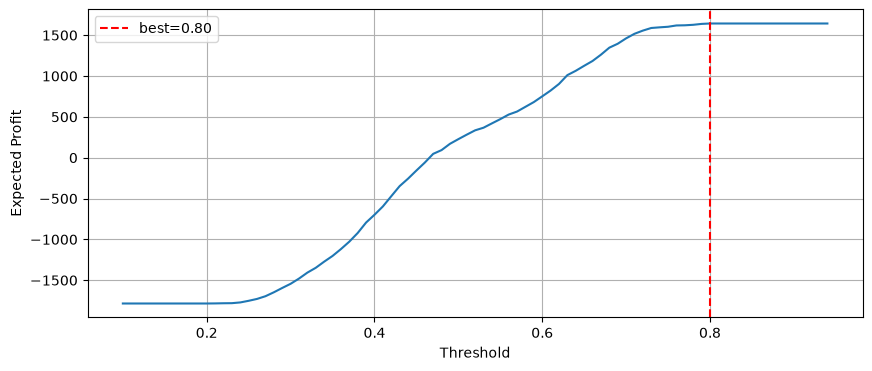

In [126]:
thresholds = np.arange(0.10, 0.95, 0.01)
profits = [expected_profit(y_test, y_prob_rf, t, loss_bad=5)[0] for t in thresholds]
best_t = thresholds[np.argmax(profits)]
print(f"Optimal threshold = {best_t:.2f}, Max profit = {max(profits):+.0f}")

# Plot ดู
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
plt.plot(thresholds, profits)
plt.axvline(best_t, color='red', linestyle='--', label=f'best={best_t:.2f}')
plt.xlabel('Threshold'); plt.ylabel('Expected Profit')
plt.legend(); plt.grid(True); plt.show()

In [127]:
# สมมติฐาน (ปรับตามธุรกิจจริง)
profit_per_good_loan = 1.0      # กำไรจากลูกค้าดี 1 ราย (หน่วย normalized)
loss_per_bad_loan = 5.0         # ขาดทุนจาก NPL 1 ราย

def expected_profit(y_true, y_prob, t):
    y_pred = (y_prob >= t).astype(int)
    tp = ((y_true == 1) & (y_pred == 1)).sum()   # อนุมัติหนี้เสีย (แย่)
    tn = ((y_true == 0) & (y_pred == 0)).sum()   # อนุมัติลูกค้าดี (ดี)
    fn = ((y_true == 1) & (y_pred == 0)).sum()   # ปฏิเสธหนี้เสีย (ดี)
    fp = ((y_true == 0) & (y_pred == 1)).sum()   # ปฏิเสธลูกค้าดี (แย่)
    return tn * profit_per_good_loan - tp * loss_per_bad_loan

for t in [0.20, 0.25, 0.30, 0.330, 0.40, 0.482, 0.55]:
    p = expected_profit(y_test, y_prob_rf, t)
    print(f"t={t:.3f} | Expected Profit = {p:+.0f}")


t=0.200 | Expected Profit = -1785
t=0.250 | Expected Profit = -1752
t=0.300 | Expected Profit = -1544
t=0.330 | Expected Profit = -1348
t=0.400 | Expected Profit = -699
t=0.482 | Expected Profit = +119
t=0.550 | Expected Profit = +472


In [128]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get probability of default
y_prob_rf = model_rf.predict_proba(x_test)[:, 1]

thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

for threshold in thresholds:

    y_pred_threshold = (y_prob_rf >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1-score: {f1:.3f}")


Threshold: 0.25
Precision: 0.181
Recall: 1.000
F1-score: 0.307

Threshold: 0.3
Precision: 0.194
Recall: 0.975
F1-score: 0.323

Threshold: 0.35
Precision: 0.211
Recall: 0.913
F1-score: 0.343

Threshold: 0.4
Precision: 0.240
Recall: 0.804
F1-score: 0.370

Threshold: 0.45
Precision: 0.281
Recall: 0.667
F1-score: 0.395

Threshold: 0.5
Precision: 0.321
Recall: 0.557
F1-score: 0.407

Threshold: 0.55
Precision: 0.351
Recall: 0.479
F1-score: 0.405

Threshold: 0.6
Precision: 0.384
Recall: 0.378
F1-score: 0.381


In [129]:
# Tunning Randomforest


from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, f1_score
param_grid = {
    "classifier__n_estimators": [100, 200, 300, 500],

    "classifier__max_depth": [5, 8, 12, 15, 20, None],

    "classifier__min_samples_split": [2, 5, 10, 15],

    "classifier__min_samples_leaf": [1, 2, 4, 8],

    "classifier__max_features": ["sqrt", "log2", 0.5],

    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

random_search = RandomizedSearchCV(
    estimator=model_rf,
    param_distributions=param_grid,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Search for best parameters
random_search.fit(x_train, y_train)

# Get best model
best_rf_model = random_search.best_estimator_

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross Validation F1:")
print(random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'classifier__n_estimators': 500, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced_subsample'}

Best Cross Validation F1:
0.40819674242122767


In [130]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get probability of default
y_prob_rf = model_rf.predict_proba(x_test)[:, 1]

thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

for threshold in thresholds:

    y_pred_threshold = (y_prob_rf >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1-score: {f1:.3f}")


Threshold: 0.25
Precision: 0.181
Recall: 1.000
F1-score: 0.307

Threshold: 0.3
Precision: 0.194
Recall: 0.975
F1-score: 0.323

Threshold: 0.35
Precision: 0.211
Recall: 0.913
F1-score: 0.343

Threshold: 0.4
Precision: 0.240
Recall: 0.804
F1-score: 0.370

Threshold: 0.45
Precision: 0.281
Recall: 0.667
F1-score: 0.395

Threshold: 0.5
Precision: 0.321
Recall: 0.557
F1-score: 0.407

Threshold: 0.55
Precision: 0.351
Recall: 0.479
F1-score: 0.405

Threshold: 0.6
Precision: 0.384
Recall: 0.378
F1-score: 0.381


                            Feature  Importance
5                 num__credit_score    0.414134
6           num__credit_utilization    0.226089
10          num__late_payment_count    0.116931
3        num__total_account_balance    0.036880
1               num__monthly_income    0.035721
4                   num__total_debt    0.033846
7                  num__loan_amount    0.029440
2     num__employment_tenure_months    0.028402
0                 num__customer_age    0.019623
9          num__previous_loan_count    0.014088
8             num__loan_term_months    0.009871
24  cat__employment_type_Unemployed    0.007259
15          cat__education_Bachelor    0.004123
16           cat__education_Diploma    0.002299
21   cat__employment_type_Full-time    0.002261


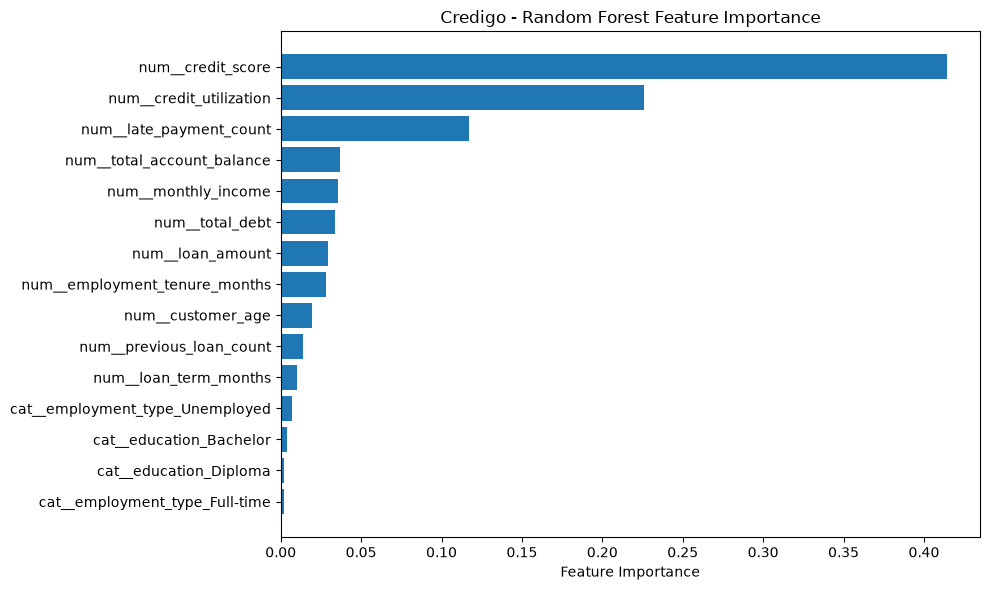

In [131]:
import pandas as pd
import matplotlib.pyplot as plt

# Get trained Random Forest
rf = model_rf.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = model_rf.named_steps["preprocess"].get_feature_names_out()

# Feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

# Plot
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"].head(15)[::-1],
    importance_df["Importance"].head(15)[::-1]
)

plt.xlabel("Feature Importance")
plt.title("Credigo - Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [132]:
'''
param_grid_xgb = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5, 7],
    "classifier__reg_lambda": [1, 3, 5, 10]
}

random_search_xgb = RandomizedSearchCV(
    estimator=model_xg,
    param_distributions=param_grid_xgb,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_xgb.fit(x_train, y_train)

best_xgb_model = random_search_xgb.best_estimator_

print("Best Parameters:")
print(random_search_xgb.best_params_)

print("Best CV F1:")
print(random_search_xgb.best_score_)

'''

'\nparam_grid_xgb = {\n    "classifier__n_estimators": [100, 200, 300, 500],\n    "classifier__max_depth": [2, 3, 4, 5, 6],\n    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],\n    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],\n    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],\n    "classifier__min_child_weight": [1, 3, 5, 7],\n    "classifier__reg_lambda": [1, 3, 5, 10]\n}\n\nrandom_search_xgb = RandomizedSearchCV(\n    estimator=model_xg,\n    param_distributions=param_grid_xgb,\n    n_iter=30,\n    scoring="f1",\n    cv=5,\n    random_state=42,\n    n_jobs=-1,\n    verbose=1\n)\n\nrandom_search_xgb.fit(x_train, y_train)\n\nbest_xgb_model = random_search_xgb.best_estimator_\n\nprint("Best Parameters:")\nprint(random_search_xgb.best_params_)\n\nprint("Best CV F1:")\nprint(random_search_xgb.best_score_)\n\n'

In [133]:
#joblib.dump(model_rf,"random_forest_model.pkl")

In [134]:

import joblib

MODEL_PATH = r"C:\Users\Ittikorn\Music\Credigo\ml_training\random_forest_model.pkl"

joblib.dump(model_rf, MODEL_PATH)

print("Model saved successfully!")


Model saved successfully!


In [135]:
import joblib

MODEL_PATH = r"C:\Users\Ittikorn\Music\Credigo\ml_training\random_forest_model.pkl"

model = joblib.load(MODEL_PATH)

print("Model loaded successfully!")
print("Model type:", type(model))
for step_name, step_object in model.named_steps.items():
    print("\nStep:", step_name)
    print("Type:", type(step_object))
    
preprocessor = model.named_steps["preprocess"]

for transformer_name, transformer, columns in preprocessor.transformers_:

    print(f"\nTransformer: {transformer_name}")
    print(f"Columns: {columns}")

    if hasattr(transformer, "categories_"):
        for column, categories in zip(
            columns,
            transformer.categories_
        ):
            print(f"{column}: {categories}")

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>

Step: preprocess
Type: <class 'sklearn.compose._column_transformer.ColumnTransformer'>

Step: classifier
Type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>

Transformer: num
Columns: ['customer_age', 'monthly_income', 'employment_tenure_months', 'total_account_balance', 'total_debt', 'credit_score', 'credit_utilization', 'loan_amount', 'loan_term_months', 'previous_loan_count', 'late_payment_count']

Transformer: cat
Columns: ['marital_status', 'education', 'employment_type']
marital_status: ['Divorced' 'Married' 'Single' 'Widowed']
education: ['Bachelor' 'Diploma' 'Doctorate' 'High School' 'Master']
employment_type: ['Freelance' 'Full-time' 'Part-time' 'Self-employed' 'Unemployed']


In [136]:
import joblib
from pathlib import Path

model = joblib.load(
    Path(MODEL_PATH)
)

preprocessor = model.named_steps["preprocessor"]

for name, categories in zip(
    preprocessor.transformers_[0][2],
    preprocessor.transformers_[0][1].categories_
):
    print(name, categories)

KeyError: 'preprocessor'